### **Single Cell Application: RNA velocity**

**Instructors:**  
Zongxu Zhang ([zongxu.zhang@stu.pku.edu.cn](mailto:zongxu.zhang@stu.pku.edu.cn))  
Zexian Zeng ([zexianzeng@pku.edu.cn](mailto:zexianzeng@pku.edu.cn))  

**Affiliation:**  
Center for Quantitative Biology  
Academy for Advanced Interdisciplinary Studies  
Peking University  

**Lab Website:**  
🔗 [http://cqb.pku.edu.cn/zenglab/](http://cqb.pku.edu.cn/zenglab/)
    

>  This materials is largely based on [Single cell best practice](https://www.sc-best-practices.org/trajectories/rna_velocity.html) and [scVelo](https://scvelo.readthedocs.io/en/stable/index.html), we thank the origional authors for their contribution.

#### **Review of Last Week’s Topics**

0. **Basic scRNA-seq Mapping Process**  
   Overview of the standard single-cell RNA-sequencing (scRNA-seq) analysis workflow — from raw read alignment and expression matrix generation to downstream preprocessing steps.

1. **R-based Workflow: Seurat**  
   Introduction to the *Seurat* package for scRNA-seq data preprocessing and analysis, including:
   - Quality control and filtering  
   - Identification of highly variable genes  
   - Data normalization and scaling  
   - Dimensionality reduction (PCA, UMAP, t-SNE)  
   - Cell clustering and visualization  
   - Annotation and dataset integration  

2. **Python-based Workflow: Scanpy**  
   Overview of the *Scanpy* package as a Python counterpart to Seurat, supporting similar functions for data preprocessing, clustering, and visualization in a scalable, efficient framework.

> 💡 **Note:** This course will primarily focus on Python-based workflows for scRNA-seq data analysis.

### Introduction to gene expression velocity modeling

#### 1. Gene expression stability

Sui et al. (PMID: 15903968) have experimentally demonstrated for the first time that gene regulatory networks in real cells can exhibit high-dimensional stable attractors, with cell fate (cell state) corresponding to a stable attractor state within the gene expression space.

<img src="./img/stability.png" width="300">

2773-dimensional gene expression state space:
-  HL60 progenitor cell differentiation into neutriphil triggered by DMSO & atRA.
-  Their gene expression coverage at the same steady state.

#### 2. Pre-mRNA and mRNA dynamics encode celluar response to stimuli

$$
\begin{aligned}
\frac{dP}{dt} &= \beta(t) - \alpha_1 P(t),\\[4pt]
\frac{dM}{dt} &= \alpha_1 P(t) - \alpha_2(t) M(t).
\end{aligned}
$$

Such equation express the dynamic of pre and mature RNA changes w.r.t. time. (PMID: 21915116)

<img src="./img/func.png" width="500">

However, in scRNA-seq data, time is also unkown.

#### 3. Intron and exon value from scRNA-seq data encode dynamic

Different conditions affect the transcription dynamic of genes. (PMID: 21915116)

Such things can be measured by RNA-seq.


<img src="./img/intron-exon.png" width="400">

#### 4. RNA velocity: steady-state estimation of celluar velocity

The first attempt at estimating RNA velocity assumed gene independence and the underlying kinetics to be governed by the above model. (PMID: 30089906)

Additionally, it is assumed that:\
(1) kinetics reached their equilibrium,\
(2) rates are constant, and\
(3) there is a single, common splicing rate across all genes. 

In the following, we will refer to this model as the steady-state model due to the first assumption. The steady-states itself are found in the upper right corner of the phase portrait (induction phase) and its origin (repression phase). Based on these extreme quantiles, the steady-state model estimates the steady-state ratio with a linear regression fit. RNA velocity is then defined as the residual to this fit.

<img src="./img/sss.png" width="600">

> Relations to first order ODE<img src="./img/ssd.png" width="600">

Solving the equation and estimated the solution witout knowing time:

<img src="./img/sst.png" width="600">

<img src="./img/ss1.png" width="600">

Even though the steady-state model can successfully recover the developmental direction in some systems, it is inherently limited by its model assumptions. 

The two assumptions readily violated are the common splicing rate across genes and that the equilibria are observed during the experiment. 

Consequently, inference in these cases will yield incorrect results. Additionally, the steady-state model only considers a subset of the data, and only the steady-state ratio but not each model parameter is inferred.

#### 5. RNA velocity: dynamical modeling

To overcome the limitations of the steady-state model, several extensions have been proposed. The so-far most popular one is the EM model implemented in scVelo. 

The EM model no longer assumes that steady-states have been reached or that genes share a common splicing rate. 

Additionally, all datapoints are used to infer the full set of parameters as well as a gene and cell specific latent time of the splicing model. The algorithm uses an expectation-maximization (EM) framework to estimate parameters. The unobserved variables found in the E-step consist of each cell’s time and state (induction, repression, or steady-state). All other model parameters are inferred during the M-step.

<img src="./img/scvelo.png" width="600">

While the EM model no longer relies on key assumptions of the steady-state model and, thus, is more broadly applicable, the inferred RNA velocity may still violate prior biological knowledge. 

The reason for such failure cases are mainly two-fold: On the one hand, the EM model continues to assume constant rates. Consequently, whenever these assumption does not hold, for example in erythroid maturation, the inference is incorrect. On the other hand, the proposed model relies on phase portraits as its predecessor. As such, the algorithm is inherently inapplicable and fails whenever the gene phase portraits do not follow the expected shape.

#### 6. Forming discrete velocity vector into continuous fields

<img src="./img/label.png" width="600">

For more information, please refer to Dynamo.

### A simple case for steady-state RNA velocity

It is applied to endocrine development in the pancreas, with lineage commitment to four major fates: α, β, δ and ε-cells. <br/> 

Pancreatic epithelial and Ngn3-Venus fusion (NVF) cells during secondary transition with transcriptome profiles sampled from embryonic day 15.5.

Endocrine cells are derived from endocrine progenitors located in the pancreatic epithelium. Endocrine commitment terminates in four major fates: glucagon- producing α-cells, insulin-producing β-cells, somatostatin-producing δ-cells and ghrelin-producing ε-cells.

See [here](https://scvelo.readthedocs.io/en/stable/scvelo.datasets.pancreas.html) for more details. It can be applied to your own data along the same lines. 

In [ ]:
# update to the latest version, if not done yet.
!pip install scvelo --upgrade --quiet

In [19]:
import scvelo as scv
import scanpy as sc

In [20]:
scv.settings.verbosity = 3  # show errors(0), warnings(1), info(2), hints(3)
scv.settings.presenter_view = True  # set max width size for presenter view
scv.set_figure_params('scvelo')  # for beautified visualization

In [21]:
### Load the Data

The analysis is based on the in-built [pancreas data](https://scvelo.readthedocs.io/scvelo.datasets.pancreas) of scvelo.<br/>
To run velocity analysis on your own data, read your file (loom, h5ad, csv …) to an AnnData object with `adata = scv.read('path/file.loom', cache=True)`. If you want to merge your loom file into an already existing AnnData object, use `scv.utils.merge(adata, adata_loom)`.

In [22]:
adata = scv.datasets.pancreas()
adata

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

##### Get to know anndata, basic data structure in python for single cell analysis

<img src="https://raw.githubusercontent.com/scverse/anndata/main/docs/_static/img/anndata_schema.svg" alt="alt text" width="500px">

In [23]:
# X for sorting counts matrix, typically in Compressed Sparse Row format
adata.X

<3696x27998 sparse matrix of type '<class 'numpy.float32'>'
	with 9298890 stored elements in Compressed Sparse Row format>

In [24]:
# see what exactly does X have
print(adata.X[:5,:10]) # Slice to get the first 5 cells and first 10 genes.

In [25]:
# convert it to a numpy array
adata.X.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [26]:
adata.X.toarray().shape

(3696, 27998)

In [27]:
# different layer sorted for different gene counts,
# which is used for calculate RNA velocity
# to call this for you data, please refer to velocyto
adata.layers['spliced'], adata.layers['unspliced']

(<3696x27998 sparse matrix of type '<class 'numpy.float32'>'
 	with 9298890 stored elements in Compressed Sparse Row format>,
 <3696x27998 sparse matrix of type '<class 'numpy.float32'>'
 	with 3156504 stored elements in Compressed Sparse Row format>)

In [28]:
# adata.obs sorted cell meta data, include cluser and some specific score
adata.obs.head(3)

,clusters_coarse,clusters,S_score,G2M_score
index,,,,
AAACCTGAGAGGGATA,Pre-endocrine,Pre-endocrine,-0.224902,-0.252071
AAACCTGAGCCTTGAT,Ductal,Ductal,-0.014707,-0.232610
AAACCTGAGGCAATTA,Endocrine,Alpha,-0.171255,-0.286834


In [29]:
# adata.var sorted gene meta data
adata.var.head(3)

,highly_variable_genes
index,
Xkr4,False
Gm37381,NaN
Rp1,NaN


In [30]:
# adata.obsm sorted some coordinated of cell
adata.obsm

AxisArrays with keys: X_pca, X_umap

#### Check spliced and unspliced reads

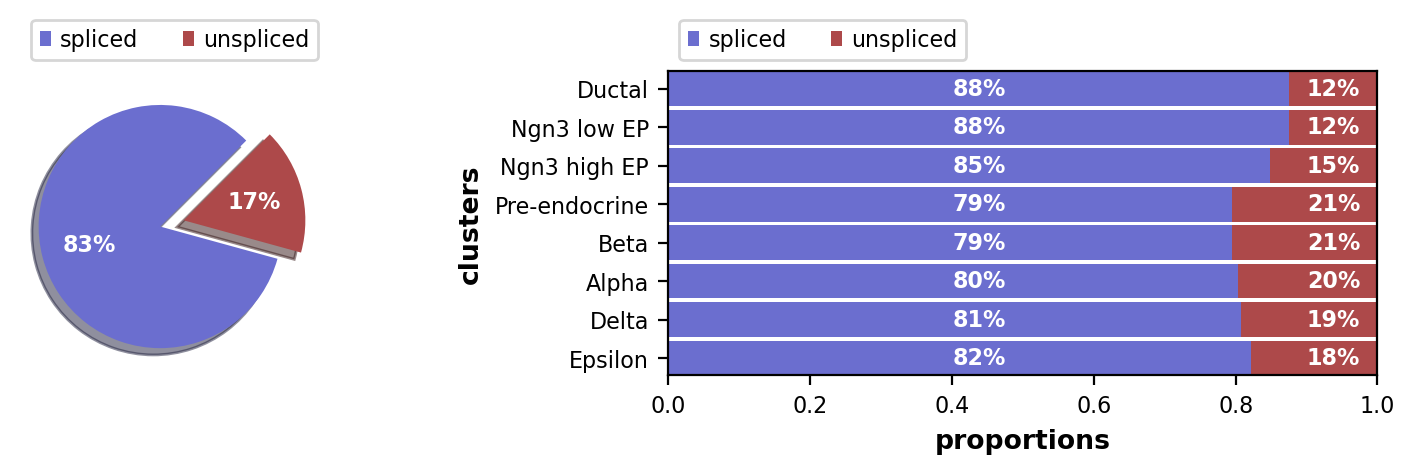

In [31]:
scv.pl.proportions(adata)

Here, the proportions of spliced/unspliced counts are displayed. Depending on the protocol used (Drop-Seq, Smart-Seq), we typically have between 10%-25% of unspliced molecules containing intronic sequences. We also advice you to examine the variations on cluster level to verify consistency in splicing efficiency. Here, we find variations as expected, with slightly lower unspliced proportions at cycling ductal cells, then higher proportion at cell fate commitment in Ngn3-high and Pre-endocrine cells where many genes start to be transcribed.

#### 0. Data preprocessing

In [32]:
scv.pp.filter_and_normalize(
    adata,
    min_shared_counts=20
)
sc.pp.log1p(adata)

Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.


In [33]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat",
    subset=True
)
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)

/tmp/ipykernel_113258/689779478.py:7: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata, n_pcs=30, n_neighbors=30)
/home/zongxu/miniconda3/envs/spatialCC/lib/python3.11/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


computing neighbors


2026-11-02 16:37:28.926575: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-02 16:37:28.946874: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793608648.962787  113258 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793608648.967241  113258 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-02 16:37:28.984838: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

    finished (0:00:11) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


#### 1. Estimate RNA velocity

Velocities are vectors in gene expression space and represent the direction and speed of movement of the individual cells. The velocities are obtained by modeling transcriptional dynamics of splicing kinetics, either stochastically (default) or deterministically (by setting ``mode='deterministic'``). 

For each gene, a steady-state-ratio of pre-mature (unspliced) and mature (spliced) mRNA counts is fitted, which constitutes a constant transcriptional state. Velocities are then obtained as residuals from this ratio. Positive velocity indicates that a gene is up-regulated, which occurs for cells that show higher abundance of unspliced mRNA for that gene than expected in steady state. Conversely, negative velocity indicates that a gene is down-regulated.

The solution to the full dynamical model is obtained by setting ``mode='dynamical'``, which requires to run
``scv.tl.recover_dynamics(adata)`` beforehand. See here for more informations.

In [34]:
scv.tl.velocity(adata)

computing velocities


/home/zongxu/miniconda3/envs/spatialCC/lib/python3.11/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


The computed velocities are stored in ``adata.layers`` just like the count matrices. 

The combination of velocities across genes can then be used to estimate the future state of an individual cell. In order to project the velocities into a lower-dimensional embedding, transition probabilities of cell-to-cell transitions are estimated. That is, for each velocity vector we find the likely cell transitions that are accordance with that direction. 

The transition probabilities are computed using cosine correlation between the potential cell-to-cell transitions and the velocity vector, and are stored in a matrix denoted as velocity graph. The resulting velocity graph has dimension $n_{obs} \times n_{obs}$ and summarizes the possible cell state changes that are well explained through the velocity vectors (for runtime speedup it can also be computed on reduced PCA space by setting `approx=True`).

In [35]:
scv.tl.velocity_graph(adata)

computing velocity graph (using 1/96 cores)


  0%|          | 0/3696 [00:00<?, ?cells/s]

    finished (0:00:08) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


For a variety of applications, the velocity graph can be converted to a transition matrix by applying a Gaussian kernel to transform the cosine correlations into actual transition probabilities. You can access the Markov transition matrix via `scv.utils.get_transition_matrix`. 

As mentioned, it is internally used to project the velocities into a low-dimensional embedding by applying the mean transition with respect to the transition probabilities, obtained with `scv.tl.velocity_embedding`. Further, we can trace cells along the Markov chain to their origins and potential fates, thereby getting root cells and end points within a trajectory, obtained via `scv.tl.terminal_states`.

#### 2. Project the velocities

Finally, the velocities are projected onto any embedding, specified by `basis`, and visualized in one of these ways: 
- on cellular level with `scv.pl.velocity_embedding`,
- as gridlines with `scv.pl.velocity_embedding_grid`,
- or as streamlines with `scv.pl.velocity_embedding_stream`.

Note, that the data has an already pre-computed UMAP embedding, and annotated clusters. When applying to your own data, these can be obtained with `scv.tl.umap` and `scv.tl.louvain`. For more details, see the [scanpy tutorial](https://scanpy-tutorials.readthedocs.io/en/latest/pbmc3k.html). Further, all plotting functions are defaulted to using `basis='umap'` and `color='clusters'`, which you can set accordingly.

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


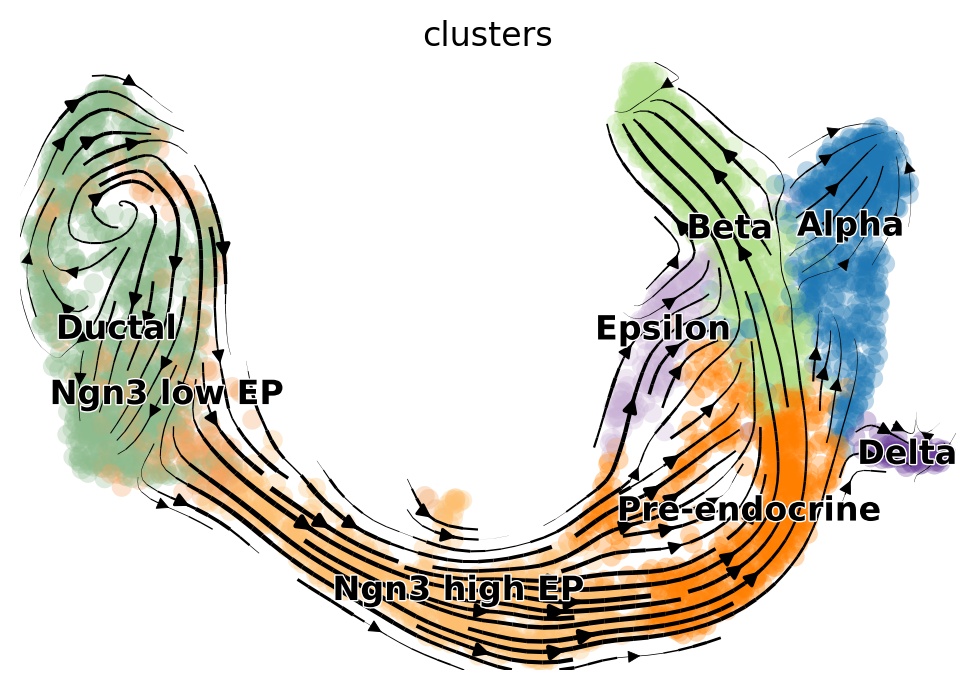

In [36]:
scv.pl.velocity_embedding_stream(adata, basis='umap')

The velocity vector field displayed as streamlines yields fine-grained insights into the developmental processes. It accurately delineates the cycling population of ductal cells and endocrine progenitors. Further, it illuminates cell states of lineage commitment, cell-cycle exit, and endocrine cell differentiation. 

The most fine-grained resolution of the velocity vector field we get at single-cell level, with each arrow showing the direction and speed of movement of an individual cell. That reveals, e.g., the early endocrine commitment of Ngn3-cells (yellow) and a clear-cut difference between near-terminal α-cells (blue) and transient β-cells (green).

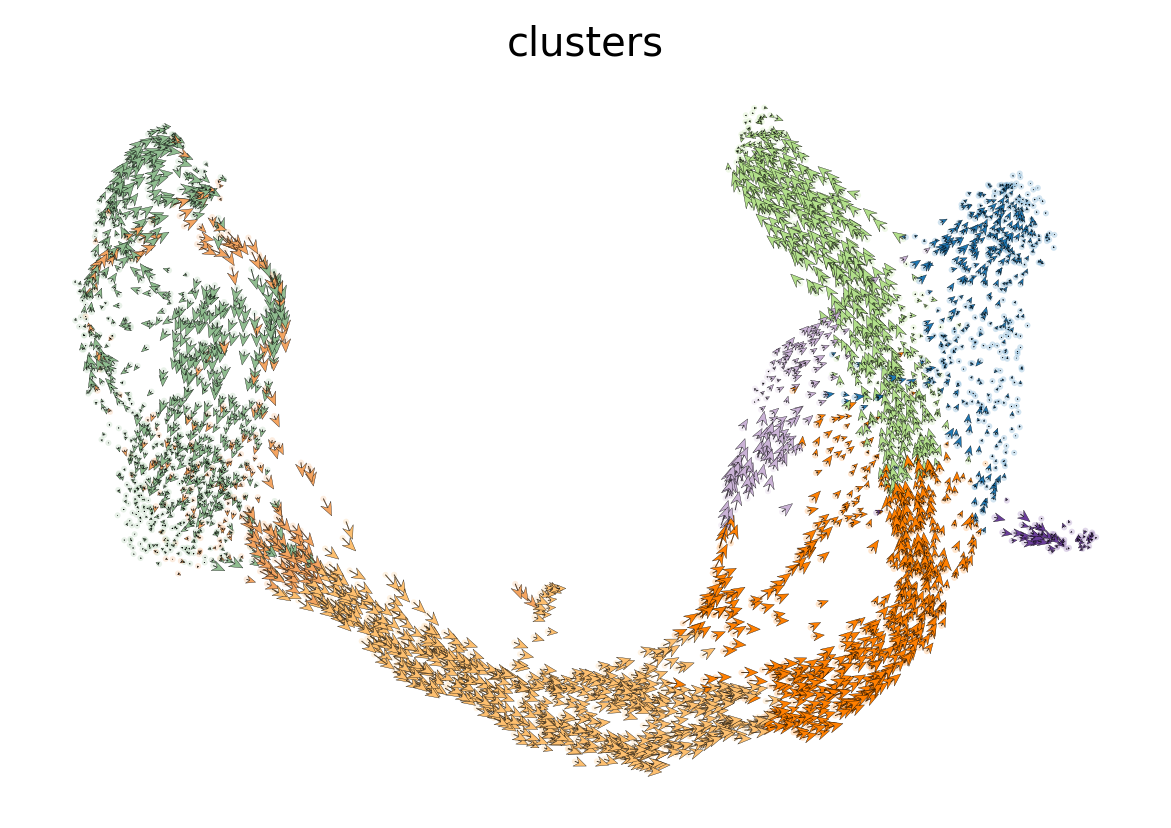

In [37]:
scv.pl.velocity_embedding(adata, arrow_length=3, arrow_size=2, dpi=120)

#### 3. Interprete the velocities

This is perhaps the most important part as we advise the user not to limit biological conclusions to the projected velocities, but to examine individual gene dynamics via phase portraits to understand how inferred directions are supported by particular genes. 

See the gif [here](https://user-images.githubusercontent.com/31883718/80227452-eb822480-864d-11ea-9399-56886c5e2785.gif) to get an idea of how to interpret a spliced vs. unspliced phase portrait. Gene activity is orchestrated by transcriptional regulation. Transcriptional induction for a particular gene results in an increase of (newly transcribed) precursor unspliced mRNAs while, conversely, repression or absence of transcription results in a decrease of unspliced mRNAs. Spliced mRNAs is produced from unspliced mRNA and follows the same trend with a time lag. Time is a hidden/latent variable. Thus, the dynamics needs to be inferred from what is actually measured: spliced and unspliced mRNAs as displayed in the phase portrait. 

Now, let us examine the phase portraits of some marker genes, visualized with <br/> 
`scv.pl.velocity(adata, gene_names)` or `scv.pl.scatter(adata, gene_names)`. 

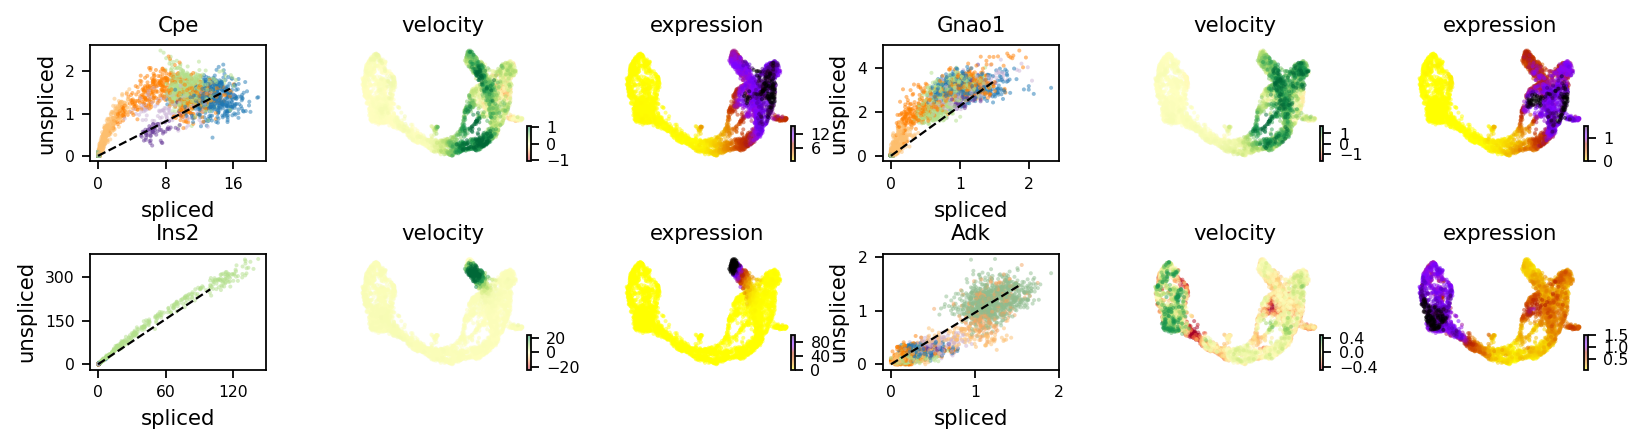

In [38]:
scv.pl.velocity(adata, ['Cpe',  'Gnao1', 'Ins2', 'Adk'], ncols=2)

The black line corresponds to the estimated 'steady-state' ratio, i.e. the ratio of unspliced to spliced mRNA abundance which is in a constant transcriptional state. RNA velocity for a particular gene is determined as the residual, i.e. how much an observation deviates from that steady-state line. Positive velocity indicates that a gene is up-regulated, which occurs for cells that show higher abundance of unspliced mRNA for that gene than expected in steady state. Conversely, negative velocity indicates that a gene is down-regulated.

For instance *Cpe* explains the directionality in the up-regulated Ngn3 (yellow) to Pre-endocrine (orange) to β-cells (green), while *Adk*  explains the directionality in the down-regulated Ductal (dark green) to Ngn3 (yellow) to the remaining endocrine cells.

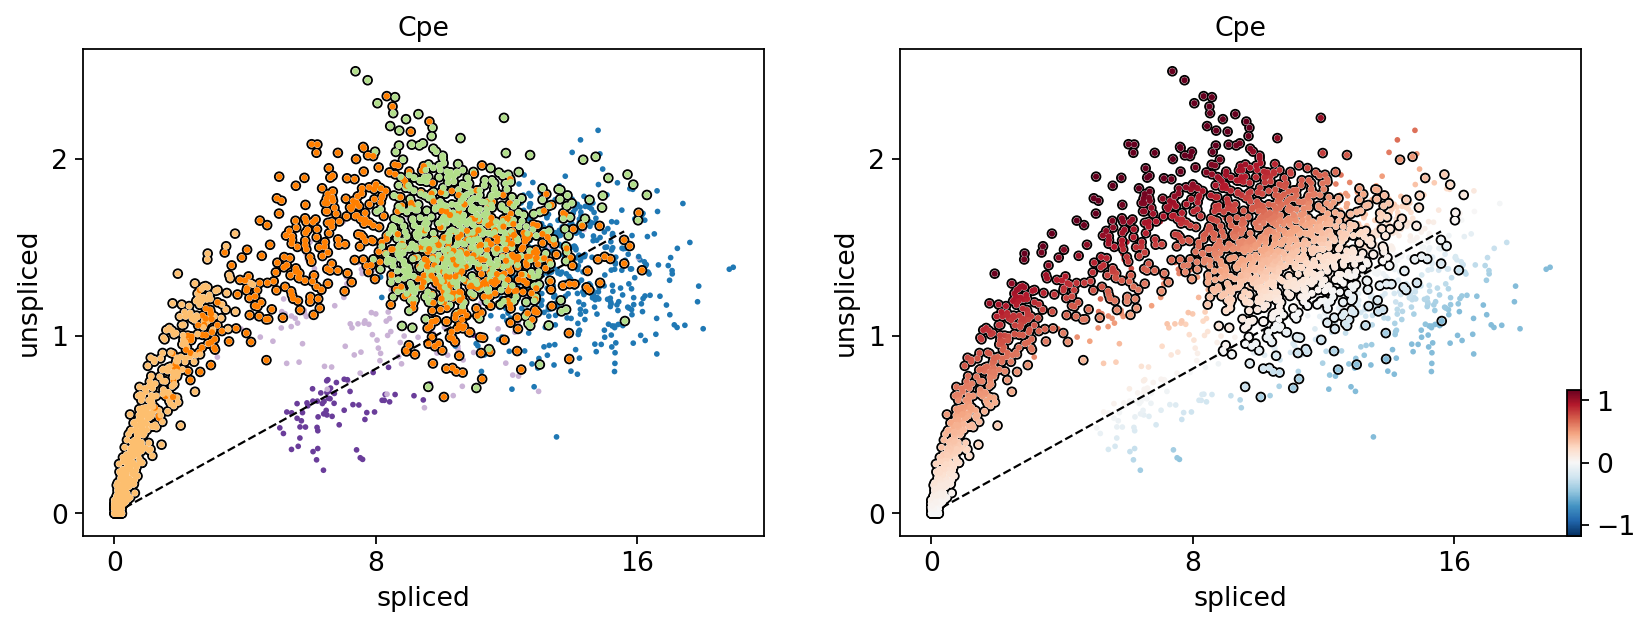

In [39]:
scv.pl.scatter(adata, 'Cpe', color=['clusters', 'velocity'], 
               add_outline='Ngn3 high EP, Pre-endocrine, Beta')

#### 4. Identify important genes

We need a systematic way to identify genes that may help explain the resulting vector field and inferred lineages. 
To do so, we can test which genes have cluster-specific differential velocity expression, being siginificantly higher/lower compared to the remaining population. The module `scv.tl.rank_velocity_genes` runs a differential velocity t-test and outpus a gene ranking for each cluster. Thresholds can be set (e.g. `min_corr`) to restrict the test on a selection of gene candidates.

In [40]:
scv.tl.rank_velocity_genes(adata, groupby='clusters', min_corr=.3)

import pandas as pd
df = pd.DataFrame(adata.uns['rank_velocity_genes']['names'])
df.head()

ranking velocity genes


/home/zongxu/miniconda3/envs/spatialCC/lib/python3.11/site-packages/scvelo/tools/utils.py:463: DeprecationWarning: Please import `rankdata` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.stats.stats import rankdata


    finished (0:00:02) --> added 
    'rank_velocity_genes', sorted scores by group ids (adata.uns) 
    'spearmans_score', spearmans correlation scores (adata.var)


,Ductal,Ngn3 low EP,Ngn3 high EP,Pre-endocrine,Beta,Alpha,Delta,Epsilon
0,Notch2,Ptpn3,Pde1c,Pam,Pax6,Zcchc16,Zdbf2,Tmcc3
1,Sox5,Hacd1,Ptprs,Sdk1,Unc5c,Nlgn1,Spock3,Heg1
2,Krt19,Hspa8,Pclo,Baiap3,Nnat,Nell1,Akr1c19,Gpr179
3,Hspa8,Gm8113,Rap1gap2,Abcc8,Tmem108,Prune2,Ptprt,Ica1
4,Ano6,Kcnq1,Ttyh2,Gnas,Ptprt,Ksr2,Snap25,Ncoa7


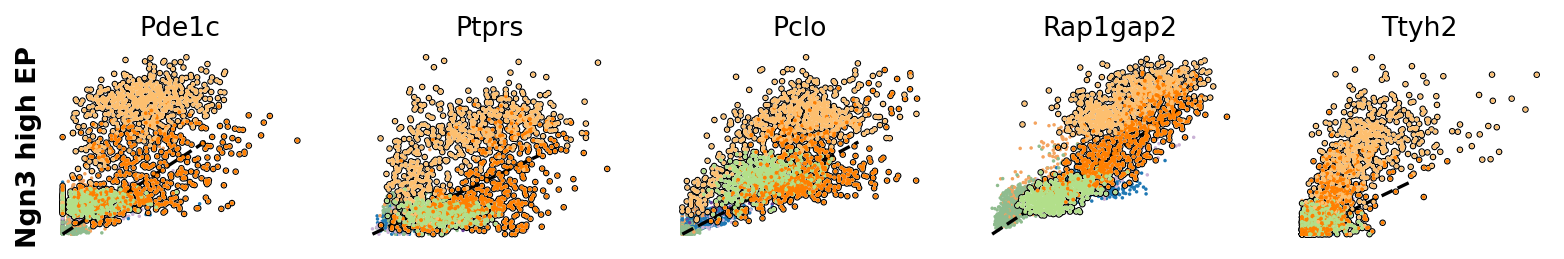

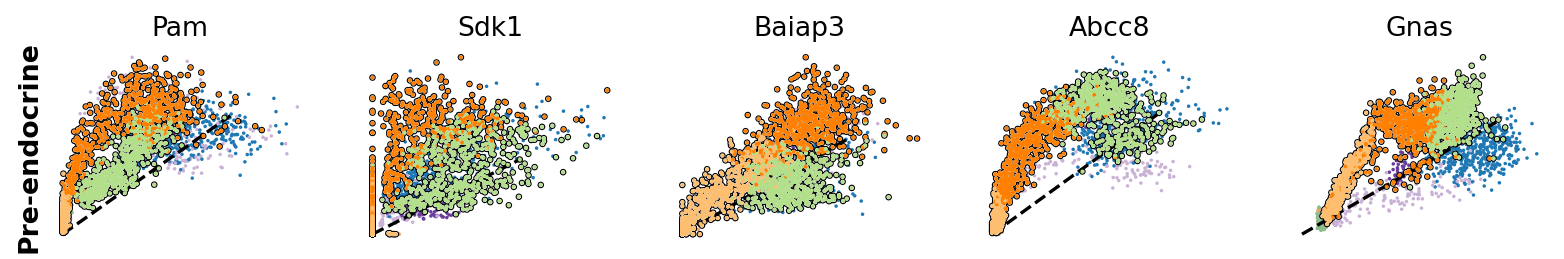

In [41]:
kwargs = dict(frameon=False, size=10, linewidth=1.5, 
              add_outline='Ngn3 high EP, Pre-endocrine, Beta')

scv.pl.scatter(adata, df['Ngn3 high EP'][:5], ylabel='Ngn3 high EP', **kwargs)
scv.pl.scatter(adata, df['Pre-endocrine'][:5], ylabel='Pre-endocrine', **kwargs)

The genes *Ptprs, Pclo, Pam, Abcc8, Gnas*, for instance, support the directionality from **Ngn3 high EP** (yellow) to **Pre-endocrine** (orange) to **Beta** (green).

#### 5. Velocities in cycling progenitors

The cell cycle detected by RNA velocity, is biologically affirmed by cell cycle scores (standardized scores of mean expression levels of phase marker genes).

calculating cell cycle phase
-->     'S_score' and 'G2M_score', scores of cell cycle phases (adata.obs)


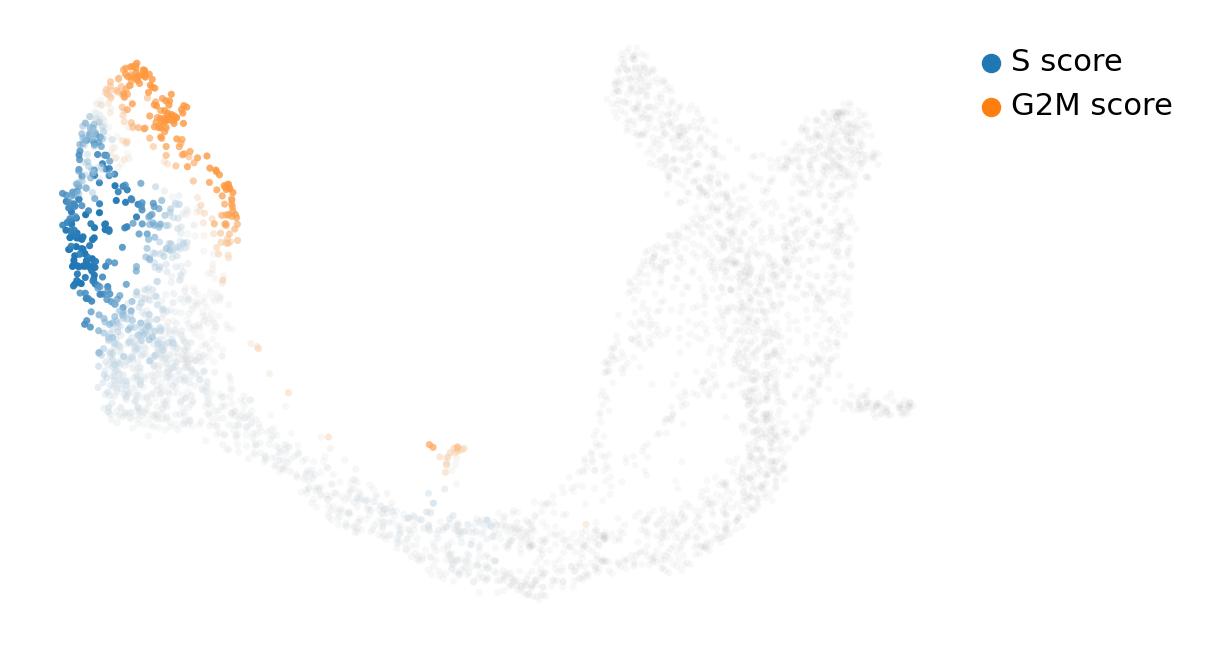

In [42]:
scv.tl.score_genes_cell_cycle(adata)
scv.pl.scatter(adata, color_gradients=['S_score', 'G2M_score'], smooth=True, perc=[5, 95])

For the cycling Ductal cells, we may screen through S and G2M phase markers. The previous module also computed a spearmans correlation score, which we can use to rank/sort the phase marker genes to then display their phase portraits. 

/tmp/ipykernel_113258/1481278250.py:2: DeprecationWarning: `get_df` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please `AnnData::get_df` or Scanpy's `scanpy.get.obs_df` or `scanpy.get.var_df`.
  s_genes = scv.get_df(adata[:, s_genes], 'spearmans_score', sort_values=True).index
/tmp/ipykernel_113258/1481278250.py:3: DeprecationWarning: `get_df` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please `AnnData::get_df` or Scanpy's `scanpy.get.obs_df` or `scanpy.get.var_df`.
  g2m_genes = scv.get_df(adata[:, g2m_genes], 'spearmans_score', sort_values=True).index


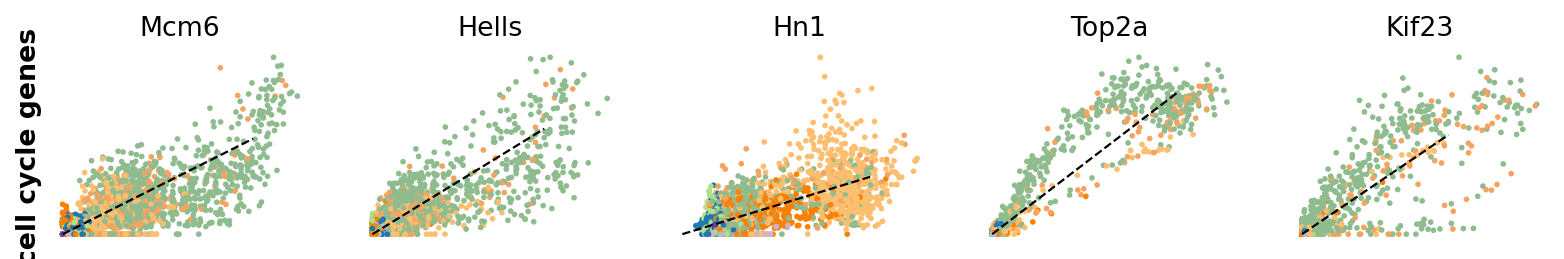

In [43]:
s_genes, g2m_genes = scv.utils.get_phase_marker_genes(adata)
s_genes = scv.get_df(adata[:, s_genes], 'spearmans_score', sort_values=True).index
g2m_genes = scv.get_df(adata[:, g2m_genes], 'spearmans_score', sort_values=True).index

kwargs = dict(frameon=False, ylabel='cell cycle genes')
scv.pl.scatter(adata, list(s_genes[:2]) + list(g2m_genes[:3]), **kwargs)

Particularly *Hells* and *Top2a* are well-suited to explain the vector field in the cycling progenitors. 
*Top2a* gets assigned a high velocity shortly before it actually peaks in the G2M phase. There, the negative velocity then perfectly matches the immediately following down-regulation. 

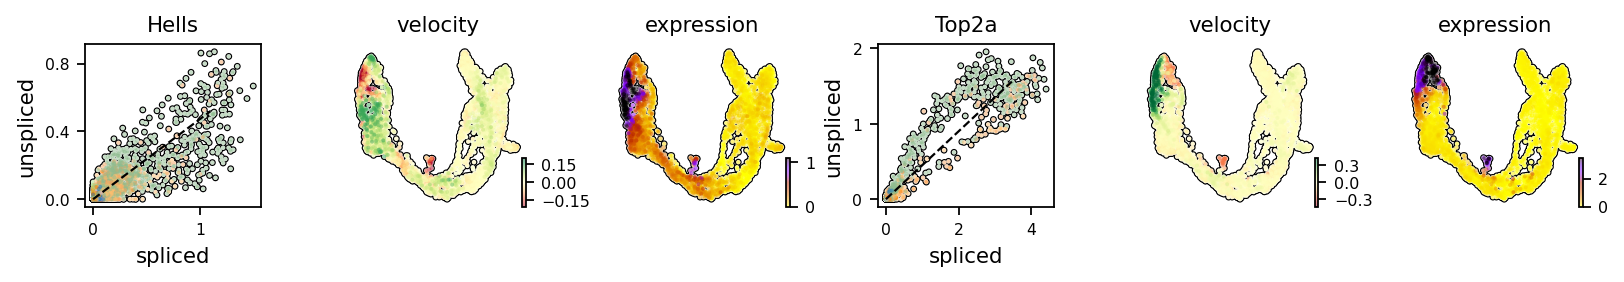

In [44]:
scv.pl.velocity(adata, ['Hells', 'Top2a'], ncols=2, add_outline=True)

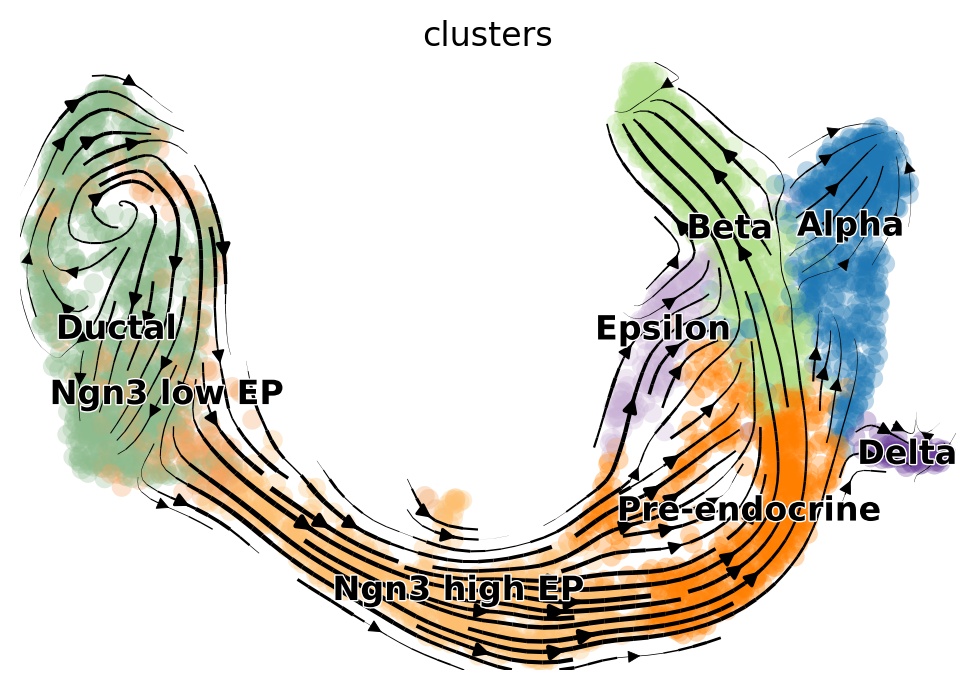

In [45]:
scv.pl.velocity_embedding_stream(adata, basis='umap')

In [46]:
import sys
import pkg_resources

print("### Session Info ###\n")

loaded_pkgs = []

for mod_name, module in sys.modules.items():
    file_path = getattr(module, "__file__", None)
    if (
        file_path
        and "site-packages" in file_path
        and not mod_name.startswith("_")
        and "." not in mod_name
    ):
        try:
            version = pkg_resources.get_distribution(mod_name).version
            loaded_pkgs.append((mod_name, version))
        except Exception:
            pass

for name, version in sorted(set(loaded_pkgs)):
    print(f"{name:<15} v{version}")

### Session Info ###

IPython         v8.20.0
anndata         v0.11.4
asciitree       v0.3.3
asttokens       v2.4.1
astunparse      v1.6.3
brotli          v1.1.0
certifi         v2025.7.14
cffi            v1.16.0
chardet         v5.2.0
charset_normalizer v3.3.2
cloudpickle     v3.0.0
colorama        v0.4.6
comm            v0.2.1
cycler          v0.12.1
cytoolz         v0.12.2
dask            v2024.7.1
debugpy         v1.8.0
decorator       v5.1.1
deprecated      v1.3.1
etils           v1.9.4
executing       v2.0.1
flatbuffers     v24.3.25
gast            v0.6.0
h5py            v3.12.1
idna            v3.6
igraph          v0.11.6
importlib_metadata v7.0.1
ipykernel       v6.29.0
ipywidgets      v8.1.9
jax             v0.4.23
jaxlib          v0.4.23
jedi            v0.19.1
jinja2          v3.1.3
joblib          v1.3.2
jupyter_client  v8.6.0
jupyter_core    v5.7.1
keras           v3.5.0
kiwisolver      v1.4.5
legacy_api_wrap v1.5
leidenalg       v0.10.2
llvmlite        v0.43.0
lz4        

#### The importance of data-preprocessing

> We show that there are substantial differences between the quantifications obtained from different tools, and identify typical genes for which such discrepancies are observed. We further show that these abundance differences propagate to the downstream analysis, and can have a large effect on estimated velocities as well as the biological interpretation.

Refer to https://pubmed.ncbi.nlm.nih.gov/33428615/